# JADES data and label checks

Inspect the labels **before applying the metallicity cut**, with one highest-S/N valid spectrum
per JADES galaxy. Select `z_1_3.yaml` or `full.yaml` below. Other quality cuts follow the configured
JADES DataModule. This notebook does not extract CLIP latents or train a flow.

The main diagnostic is the gas-metallicity histogram and its high-end zoom. The former 0.30 cut
is compared with the relaxed configurable cut of 0.40. An upper-end label is not automatically an
incorrect fit; the fitted prior and the catalog 16/50/84 percentiles must be distinguished.


In [1]:
import sys, json, re
from pathlib import Path
import numpy as np
import yaml
import h5py
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "encoder_fusion/model/fusion.py").is_file())
FLOW_DIR = ROOT / "flow"
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "neurips"))
from encoder_spectrum.LowResPT.data.dataset import LowResDataset
from flow.data.datamodule_jades import project_path
from plotstyle import C_SPECTRUM, C_RED_BRIGHT, use_style, style_axes, fs

CONFIG = FLOW_DIR / "z_1_3.yaml"  # switch to FLOW_DIR / "full.yaml"
cfg = yaml.safe_load(CONFIG.read_text())["data"]
METALLICITY_CUT = cfg["max_gas_logz"]  # None retains every finite metallicity
use_style(1.0)


## 1. Parent sample before the metallicity cut

Use the same spectral grades, valid-pixel fraction, S/N, redshift bounds, finite p50 targets,
`z_consistent` flag and finite spectrum embeddings as the training DataModule. Deduplicate by JADES ID
using the highest S/N. The metallicity threshold is deliberately omitted here so the plot can show
what it would remove. All counts below refer to unique galaxies, not repeated spectra.


In [2]:
lab = Table.read(project_path(cfg["labels_path"]))
with fits.open(project_path(cfg["fits_path"]), memmap=True) as hdul:
    all_z = np.asarray(hdul["CATALOG"].data["z_best"], float).copy()
spectra = LowResDataset(fits_path=str(project_path(cfg["fits_path"])),
                        grades=cfg["grades"], frac_valid_pix=cfg["frac_valid_pix"])
quality_ids = spectra.valid_indices.copy()
del spectra

quantiles = {}
for q in ("p16", "p50", "p84"):
    values = np.stack([np.asarray(lab[f"{name}_{q}"], float)
                       for name in cfg["target_columns"]], axis=1)
    for name in cfg["log_columns"]:
        j = cfg["target_columns"].index(name)
        v = values[:, j]
        with np.errstate(divide="ignore", invalid="ignore"):
            values[:, j] = np.where(v > 0, np.log10(v), np.nan)
    quantiles[q] = values

with h5py.File(project_path(cfg["embeddings_path"]), "r") as f:
    ids, sn = f["id"][:], f["sn50"][:]
    group = np.asarray(lab["jades_id"])
    assert len(lab) == len(ids)
    if "dja_id" in lab.colnames:
        assert np.array_equal(lab["dja_id"], ids)
    z = all_z[ids]
    mask = ((sn > cfg["min_sn50"]) & (f["spectrum_token_mask"][:].mean(1) > cfg["frac_valid_pix"])
            & np.isin(ids, quality_ids) & (group >= 0)
            & np.isfinite(quantiles["p50"]).all(1))
    if cfg["z_consistent"]:
        mask &= np.asarray(lab["z_consistent"], bool)
    if cfg["min_redshift"] is not None:
        mask &= z > cfg["min_redshift"]
    if cfg["max_redshift"] is not None:
        mask &= z <= cfg["max_redshift"]
    candidates = np.flatnonzero(mask)
    finite = []
    for start in range(0, len(candidates), cfg["embedding_batch_size"]):
        rr = candidates[start:start + cfg["embedding_batch_size"]]
        a = f["spectrum_patch_embed"][rr]
        finite.append(np.isfinite(a).reshape(len(rr), -1).all(1))
    rows = candidates[np.concatenate(finite)] if finite else candidates

n_spectra = len(rows)
rows = rows[np.argsort(-sn[rows], kind="stable")]
_, first = np.unique(group[rows], return_index=True)
rows = np.sort(rows[first])
if not len(rows):
    raise ValueError("No galaxies pass the parent-sample cuts")
metal = np.asarray(lab["gas_logz_p50"], float)[rows]
metal16 = np.asarray(lab["gas_logz_p16"], float)[rows]
metal84 = np.asarray(lab["gas_logz_p84"], float)[rows]
retained = np.ones(len(rows), bool) if METALLICITY_CUT is None else metal <= METALLICITY_CUT
print(f"{CONFIG.name}: {n_spectra} valid spectra -> {len(rows)} unique galaxies before the metallicity cut")
print(f"gas_logz_p50 range: {metal.min():.4f} to {metal.max():.4f}")
print(f"Current cut: {METALLICITY_CUT}; keep {retained.sum()}, remove {(~retained).sum()} "
      f"({(~retained).mean():.2%})")


Converting flux from f_nu (uJy) to f_lambda (∝ f_nu / λ²) (use_jansky=True to disable this conversion)
grade in (1, 2, 3) filtering: 26486/42196 samples kept
valid_pix_frac > 0.5 filtering: 25025/42196 samples kept
LowResDataset: 25025 spectra, 56 pixels (1.004–1.991 µm)
z_1_3.yaml: 1218 valid spectra -> 1070 unique galaxies before the metallicity cut
gas_logz_p50 range: -1.7287 to 0.3942
Current cut: 0.4; keep 1070, remove 0 (0.00%)


## 2. Gas-metallicity histogram and the upper tail

The gas metallicity is already $\log_{10}(Z_{\rm gas}/Z_\odot)$ in the label catalog; do not log it again.
The fit prior is read from the locally downloaded `extra_young_ns` metadata. Its upper bound is a
separate quantity from our selectable p50 threshold. The histogram uses the original 80-bin style,
with a zoom to make the few highest values visible.


Fitted gas-metallicity prior: Uniform(-2.0, 0.5) (from runs.json)


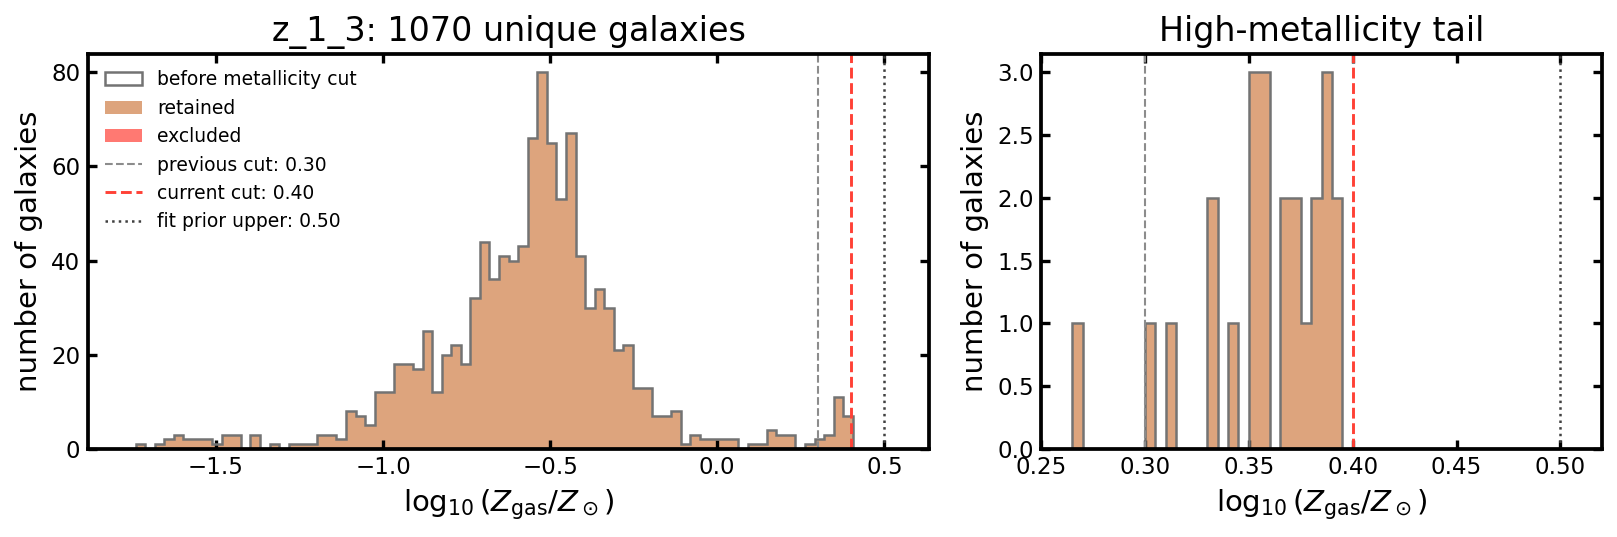

In [3]:
metadata_path = ROOT / "data/survey/JADES/prospector_fit_explorer/runs.json"
metadata = json.loads(metadata_path.read_text())
run = next(r for r in metadata["runs"] if r["name"] == "extra_young_ns")
prior_text = next(value for name, value in run["priors_table"] if name == "log Z_gas/Z_sun")
match = re.search(r"Uniform\(([^,]+),\s*([^)]+)\)", prior_text)
prior_lower, prior_upper = map(float, match.groups())
print(f"Fitted gas-metallicity prior: {prior_text} (from {metadata_path.name})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
for ax, bins in zip(axes, [np.linspace(metal.min() - 0.04, prior_upper + 0.02, 81),
                          np.linspace(0.25, prior_upper + 0.02, 55)]):
    ax.hist(metal, bins=bins, histtype="step", color="0.45", lw=1.2, label="before metallicity cut")
    ax.hist(metal[retained], bins=bins, color=C_SPECTRUM, alpha=0.6, label="retained")
    ax.hist(metal[~retained], bins=bins, color=C_RED_BRIGHT, alpha=0.7, label="excluded")
    ax.axvline(0.30, color="0.55", ls="--", lw=1.0, label="previous cut: 0.30")
    if METALLICITY_CUT is not None:
        ax.axvline(METALLICITY_CUT, color=C_RED_BRIGHT, ls="--", lw=1.4,
                   label=f"current cut: {METALLICITY_CUT:.2f}")
    ax.axvline(prior_upper, color="0.25", ls=":", lw=1.2, label=f"fit prior upper: {prior_upper:.2f}")
    ax.set(xlabel=r"$\log_{10}(Z_{\rm gas}/Z_\odot)$", ylabel="number of galaxies")
    style_axes(ax)
axes[0].set_title(f"{CONFIG.stem}: {len(rows)} unique galaxies")
axes[1].set(xlim=(0.25, prior_upper + 0.02), title="High-metallicity tail")
axes[0].legend(frameon=False, fontsize=fs(9), loc="upper left")
fig.tight_layout()
plt.show()


## 3. How much does the threshold change the sample?

Compare candidate p50 cuts before choosing one. These are descriptive sensitivity checks,
not a statistical criterion that declares a high-metallicity fit wrong. Setting the YAML value to
`null` disables this cut. Retraining is required for a changed cut to affect an existing flow.


In [4]:
thresholds = sorted(set([0.30, 0.35, 0.38, 0.39, 0.40, 0.41, prior_upper]
                        + ([] if METALLICITY_CUT is None else [float(METALLICITY_CUT)])))
sensitivity = Table(rows=[(cut, int((metal <= cut).sum()), int((metal > cut).sum()),
                          100 * (metal > cut).mean()) for cut in thresholds],
                    names=["max_gas_logz", "retained", "excluded", "excluded_percent"])
sensitivity["max_gas_logz"].format = ".2f"
sensitivity["excluded_percent"].format = ".2f"
display(sensitivity)

# Compact checks for changes in the rest of the selected population.
logmass = np.asarray(lab["logmass_p50"], float)[rows]
impact = []
for name, selected in [("before cut", np.ones(len(rows), bool)), ("retained", retained), ("excluded", ~retained)]:
    median = lambda a: float(np.median(a[selected])) if selected.any() else np.nan
    impact.append((name, int(selected.sum()), median(z[rows]), median(logmass), median(sn[rows])))
impact = Table(rows=impact, names=["sample", "N", "median_z_spec", "median_logmass", "median_sn50"])
for name in impact.colnames[2:]:
    impact[name].format = ".3f"
display(impact)


max_gas_logz,retained,excluded,excluded_percent
float64,int64,int64,float64
0.30,1047,23,2.15
0.35,1052,18,1.68
0.38,1063,7,0.65
0.39,1068,2,0.19
0.40,1070,0,0.00
0.41,1070,0,0.00
0.50,1070,0,0.00


sample,N,median_z_spec,median_logmass,median_sn50
str10,int64,float64,float64,float64
before cut,1070,2.186,8.983,4.829
retained,1070,2.186,8.983,4.829
excluded,0,nan,nan,nan


## 4. Inspect the actual highest labels and their catalog intervals

A histogram alone cannot show whether an individual posterior is truncated by the fit prior.
List p16/p50/p84 for the twelve highest medians and their distance from the prior upper bound.
These are **catalog fit intervals**, not flow uncertainties. A high p50 below the prior limit can
still be a valid high-metallicity object; inspecting its source fit is preferable to assuming it is bad.

The high-end histogram and this table support evaluating a less aggressive threshold. They do not
by themselves establish that the previous 0.30 threshold, or the current 0.40 threshold, is physically
required. Calibration results describe the population retained by whichever selection is used.


In [5]:
highest = np.argsort(metal)[-12:][::-1]
high_labels = Table({
    "jades_id": group[rows][highest],
    "z_spec": z[rows][highest], "logmass": logmass[highest],
    "p16": metal16[highest], "p50": metal[highest], "p84": metal84[highest],
    "prior_upper_minus_p50": prior_upper - metal[highest],
    "retained": retained[highest],
})
for name in ["z_spec", "logmass", "p16", "p50", "p84", "prior_upper_minus_p50"]:
    high_labels[name].format = ".4f"
display(high_labels)
for q, a in [("p16", metal16), ("p84", metal84)]:
    print(f"Finite catalog {q}: {np.isfinite(a).sum()}/{len(a)}")


Finite catalog p16: 1070/1070
Finite catalog p84: 1070/1070


jades_id,z_spec,logmass,p16,p50,p84,prior_upper_minus_p50,retained
int64,float64,float64,float64,float64,float64,float64,bool
189524,1.6145,11.4269,0.3039,0.3942,0.4663,0.1058,True
1203667,2.5930,11.0169,0.3179,0.3938,0.4671,0.1062,True
1033651,1.3596,10.6243,0.3209,0.3879,0.4569,0.1121,True
198451,2.6138,10.8524,0.3147,0.3876,0.4513,0.1124,True
1018140,1.9287,10.6814,0.3100,0.3852,0.4629,0.1148,True
208000,2.5834,11.1387,0.2951,0.3841,0.4593,0.1159,True
156224,1.5484,11.0514,0.3227,0.3802,0.4512,0.1198,True
193080,1.8979,11.0063,0.3017,0.3757,0.4550,0.1243,True
217631,1.6129,10.9212,0.3066,0.3721,0.4573,0.1279,True
